In [1]:
# import os; os.environ["EVAL_SMOKE"] = "1"

In [2]:
# 0.1  Install missing packages (only what the Kaggle image lacks)
import os, sys, subprocess, importlib.util

ON_KAGGLE = os.path.exists("/kaggle/working")
REQUIRED = {"jiwer": "jiwer", "langchain_groq": "langchain-groq", "psutil": "psutil"}
missing = [pip_name for module, pip_name in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

# ctc-segmentation ships only as source and, by default, compiles against NumPy 1.x headers,
# which fails to import under NumPy 2. Build it against the NumPy that is actually installed.
if subprocess.run([sys.executable, "-c", "import ctc_segmentation"], capture_output=True).returncode != 0:
    print("Building ctc-segmentation against the installed NumPy ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cython"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-build-isolation", "--no-deps",
                    "--force-reinstall", "--no-cache-dir", "ctc-segmentation==1.7.4"], check=True)
    subprocess.run([sys.executable, "-c", "import ctc_segmentation"], check=True)
print("packages ready")

Installing: ['jiwer', 'langchain-groq']
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.8/572.8 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 8.0 MB/s eta 0:00:00
Building ctc-segmentation against the installed NumPy ...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.6/73.6 kB 5.9 MB/s eta 0:00:00
packages ready


In [3]:
# 0.2  Imports and version record
import gc, glob, io, json, math, re, shutil, time, zipfile, datetime, platform
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import soundfile as sf
import psutil
import torch
import jiwer
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
import transformers
from packaging import version
from transformers import pipeline, WhisperFeatureExtractor, Wav2Vec2ForCTC, Wav2Vec2Processor
import ctc_segmentation

VERSIONS = {
    "python": platform.python_version(), "torch": torch.__version__, "transformers": transformers.__version__,
    "numpy": np.__version__, "pandas": pd.__version__, "pyarrow": pa.__version__, "jiwer": getattr(jiwer, "__version__", "?"),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
}
print(json.dumps(VERSIONS, indent=2))

{
  "python": "3.12.13",
  "torch": "2.10.0+cu128",
  "transformers": "5.0.0",
  "numpy": "2.0.2",
  "pandas": "2.3.3",
  "pyarrow": "24.0.0",
  "jiwer": "?",
  "gpu": "Tesla T4"
}


## 1. Configuration
All settings live here. `MODE` switches between reproducing the paper and the recommended fixes. `EVAL_SMOKE=1` (environment variable) runs a 24-utterance smoke test.

In [4]:
@dataclass
class Config:
    MODE: str = os.environ.get("EVAL_MODE", "fixed")          # "reproduce" | "fixed"
    SMOKE_TEST: bool = os.environ.get("EVAL_SMOKE", "0") == "1"    # tiny end-to-end test
    SMOKE_N_DYS: int = 16
    SMOKE_N_TEST: int = 8

    # ── paths ──────────────────────────────────────────────────────────────
    WORK_DIR: str = "/kaggle/working" if ON_KAGGLE else os.path.abspath("eval_work")
    RESUME_GLOB: str = "/kaggle/input/*" if ON_KAGGLE else ""
    DISK_QUOTA_GB: float = 20.0          # /kaggle/working output quota
    RAM_WARN_FRAC: float = 0.85

    # ── data / split (identical to the fine-tuning notebook) ──────────────
    DATASET_REPO: str = "abnerh/TORGO-database"
    LOCAL_PARQUET_GLOB: str = os.environ.get("TORGO_PARQUET_GLOB", "")   # optional local copy
    SAMPLING_RATE: int = 16_000
    SPLIT_SEED: int = 42
    TEST_SIZE: float = 0.10
    VAL_SIZE: float = 0.10
    MIN_DUR: float = 0.1
    MAX_DUR: float = 30.0
    EXPECTED_SPLIT: tuple = (13_239, 1_656, 1_655)

    # ── ASR ────────────────────────────────────────────────────────────────
    FINETUNED_ID: str = "ruch9265/distil-whisper-torgo"   # Whisper-tiny, encoder fine-tuned
    BASELINE_ID: str = "openai/whisper-tiny"
    ASR_BATCH: int = 4
    CHUNK_S: int = 30
    RUN_BASELINE: bool = True
    BASELINE_SPLITS: tuple = ("test",)

    # ── CTC alignment ──────────────────────────────────────────────────────
    W2V_ID: str = "facebook/wav2vec2-base-960h"

    # ── pauses ─────────────────────────────────────────────────────────────
    FORMAT_THRESHOLDS: tuple = (0.02, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8)
    CANDIDATE_THRESHOLD: float = 0.02    # defines the "589" analysis set
    TAU: float = 0.7                     # manual threshold; replaced by the selected one when TAU_SELECTION == "auto"
    TAU_SELECTION: str = "auto"          # "auto": data-driven rule in stage 5.0 | "manual": use TAU as given
    TUNE_GRID: tuple = tuple(np.round(np.arange(0.05, 1.51, 0.05), 2).tolist())
    MIN_MARKERS_PER_SPEAKER: int = 5     # a threshold is 'supported' if all-but-one dysarthric speakers reach this
    SWEEP: tuple = (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0)
    WINDOW: int = 2
    N_PERM: int = 2000

    # ── LLM ────────────────────────────────────────────────────────────────
    RUN_LLM: bool = True
    LLM_BACKEND: str = os.environ.get("EVAL_LLM_BACKEND", "groq")   # "groq" | "fake" (echo, for testing)
    LLM_MODEL: str = "openai/gpt-oss-120b"
    LLM_K: int = 4
    LLM_BATCH: int = 8
    LLM_CONCURRENCY: int = 1            # 1 avoids bursts of 429s on the Groq free tier
    LLM_RETRIES: int = 5
    MAX_ABS_EDITS: int = 2
    MAX_EDIT_RATIO: float = 0.40
    RUN_CONTROLS: bool = False           # also run "no_marker" and "random_marker" controls (~2x API calls)

    # ── evaluation ─────────────────────────────────────────────────────────
    N_BOOT: int = 5000
    SEED: int = 0
    SHARD_SIZE: int = 500

    # ── backups (optional) ─────────────────────────────────────────────────
    BACKUP_TO_HF: bool = True                   # push checkpoints to a PRIVATE HF dataset after each stage
    HF_DATASET_REPO: str = "Menhaz/torgo-pause-eval-fixed"
    BACKUP_TO_KAGGLE_DATASET: bool = False       # create/update a PRIVATE Kaggle dataset at the end
    KAGGLE_DATASET_HANDLE: str = "menhazulabdin/torgo-pause-eval"

    def __post_init__(self):
        assert self.MODE in ("reproduce", "fixed"), self.MODE
        if self.MODE == "reproduce":
            # CTC batches exactly as in the original run: 4, then 2 from position 13,456
            self.CTC_SCHEDULE = ((0, 4), (13_456, 2))
            self.LLM_TEMPERATURE = 0.3
            self.PROMPT_EXAMPLES = "original"
            self.LEADING_MARKER = True
        else:
            self.CTC_SCHEDULE = ((0, 1),)     # no zero-padding → identical to single-utterance alignment
            self.LLM_TEMPERATURE = 0.0
            self.PROMPT_EXAMPLES = "neutral"  # examples not taken from the evaluated hypotheses
            self.LEADING_MARKER = False
        self.RUN_NAME = f"torgo_pause_eval_{self.MODE}" + ("_smoke" if self.SMOKE_TEST else "")
        self.RUN_DIR = os.path.join(self.WORK_DIR, self.RUN_NAME)
        self.CKPT_DIR = os.path.join(self.RUN_DIR, "checkpoints")
        self.OUT_DIR = os.path.join(self.RUN_DIR, "outputs")
        self.TABLE_DIR = os.path.join(self.OUT_DIR, "tables")
        for d in (self.CKPT_DIR, self.OUT_DIR, self.TABLE_DIR):
            os.makedirs(d, exist_ok=True)

C = Config()
rng_global = np.random.default_rng(C.SEED)
print(f"MODE={C.MODE}  SMOKE_TEST={C.SMOKE_TEST}  RUN_DIR={C.RUN_DIR}")
print(f"CTC schedule={C.CTC_SCHEDULE}  LLM temperature={C.LLM_TEMPERATURE}  prompt examples={C.PROMPT_EXAMPLES}  leading marker={C.LEADING_MARKER}")

MODE=fixed  SMOKE_TEST=False  RUN_DIR=/kaggle/working/torgo_pause_eval_fixed
CTC schedule=((0, 1),)  LLM temperature=0.0  prompt examples=neutral  leading marker=False


In [5]:
# 1.1  Utilities: resource monitor, checkpoints, secrets, backups
def gb(n_bytes): return n_bytes / 1024**3

def folder_size(path):
    total = 0
    for root, _, files in os.walk(path):
        for f in files:
            try: total += os.path.getsize(os.path.join(root, f))
            except OSError: pass
    return total

def resource_report(tag=""):
    vm = psutil.virtual_memory()
    msg = (f"[{tag}] RAM {gb(vm.used):.1f}/{gb(vm.total):.1f} GB ({vm.percent:.0f}%) | "
           f"run folder {folder_size(C.RUN_DIR)/1024**2:.1f} MB | free disk {gb(shutil.disk_usage(C.WORK_DIR).free):.1f} GB")
    if torch.cuda.is_available():
        msg += (f" | GPU {gb(torch.cuda.memory_allocated()):.2f} GB (peak {gb(torch.cuda.max_memory_allocated()):.2f})"
                f" / {gb(torch.cuda.get_device_properties(0).total_memory):.1f} GB")
    print(msg)
    if vm.percent / 100 > C.RAM_WARN_FRAC:
        print(" RAM above warning level: lower ASR_BATCH / SHARD_SIZE or restart the kernel (checkpoints are kept).")
    if ON_KAGGLE and gb(folder_size(C.WORK_DIR)) > 0.9 * C.DISK_QUOTA_GB:
        print(" /kaggle/working is close to the 20 GB output quota: delete old runs or shards.")

def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

def atomic_parquet(df, path):
    tmp = path + ".tmp"
    df.to_parquet(tmp, index=False)
    os.replace(tmp, path)

def ckpt_path(name): return os.path.join(C.CKPT_DIR, f"{name}.parquet")

def load_stage(name):
    p = ckpt_path(name)
    return pd.read_parquet(p) if os.path.exists(p) else None

def save_stage(df, name):
    atomic_parquet(df, ckpt_path(name))
    print(f"{name}: {len(df):,} rows → {ckpt_path(name)}")
    write_manifest()
    backup_to_hf()

def write_manifest(extra=None):
    stages = {}
    for p in sorted(glob.glob(os.path.join(C.CKPT_DIR, "*.parquet"))):
        stages[os.path.basename(p)] = {"bytes": os.path.getsize(p),
                                       "modified": datetime.datetime.fromtimestamp(os.path.getmtime(p)).isoformat(timespec="seconds")}
    cfg = {k: (list(v) if isinstance(v, tuple) else v) for k, v in vars(C).items()}
    manifest = {"config": cfg, "versions": VERSIONS, "stages": stages,
                "written": datetime.datetime.now().isoformat(timespec="seconds")}
    if extra: manifest.update(extra)
    with open(os.path.join(C.RUN_DIR, "manifest.json"), "w") as f:
        json.dump(manifest, f, indent=2, default=str)

def get_secret(name):
    if os.environ.get(name): return os.environ[name]
    if ON_KAGGLE:
        try:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret(name)
        except Exception:
            return None
    return None

HF_TOKEN = get_secret("HF_TOKEN")

def backup_to_hf():
    if not (C.BACKUP_TO_HF and HF_TOKEN): return
    try:
        from huggingface_hub import HfApi
        api = HfApi(token=HF_TOKEN)
        api.create_repo(C.HF_DATASET_REPO, repo_type="dataset", private=True, exist_ok=True)
        api.upload_folder(folder_path=C.RUN_DIR, path_in_repo=C.RUN_NAME, repo_id=C.HF_DATASET_REPO,
                          repo_type="dataset", ignore_patterns=["*.tmp", "*.zip"])
        print(f" backed up to hf.co/datasets/{C.HF_DATASET_REPO}")
    except Exception as e:
        print(f" HF backup failed (run continues): {e}")

def restore_previous_checkpoints():
    """Copy checkpoints from attached Kaggle inputs or the HF backup into RUN_DIR (never overwrites)."""
    sources = []
    if C.RESUME_GLOB:
        sources += glob.glob(os.path.join(C.RESUME_GLOB, "**", C.RUN_NAME), recursive=True)
    if C.BACKUP_TO_HF and HF_TOKEN and not glob.glob(os.path.join(C.CKPT_DIR, "*")):
        try:
            from huggingface_hub import snapshot_download
            d = snapshot_download(C.HF_DATASET_REPO, repo_type="dataset", token=HF_TOKEN, allow_patterns=[f"{C.RUN_NAME}/*"])
            sources.append(os.path.join(d, C.RUN_NAME))
        except Exception as e:
            print(f"(no HF backup restored: {e})")
    copied = 0
    for src in sources:
        if os.path.abspath(src) == os.path.abspath(C.RUN_DIR) or not os.path.isdir(src): continue
        for root, _, files in os.walk(src):
            for f in files:
                s = os.path.join(root, f)
                d = os.path.join(C.RUN_DIR, os.path.relpath(s, src))
                if not os.path.exists(d):
                    os.makedirs(os.path.dirname(d), exist_ok=True); shutil.copy2(s, d); copied += 1
        print(f" restored from {src}")
    print(f"Checkpoint files restored: {copied}")

if HF_TOKEN:
    from huggingface_hub import login
    login(token=HF_TOKEN)
    print("Hugging Face login")
else:
    print("HF_TOKEN not set: public models only")
restore_previous_checkpoints()
resource_report("setup")

Hugging Face login


Fetching 101 files:   0%|          | 0/101 [00:00<?, ?it/s]

 restored from /root/.cache/huggingface/hub/datasets--Menhaz--torgo-pause-eval-fixed/snapshots/f83c8e1e27471bf4c6e14e2b8d56ff037a78f1ef/torgo_pause_eval_fixed
Checkpoint files restored: 101
[setup] RAM 1.3/31.3 GB (6%) | run folder 6.4 MB | free disk 19.5 GB | GPU 0.00 GB (peak 0.00) / 14.6 GB


## 2. Data and the seed-42 split
The TORGO parquet files are read directly (no `datasets` package, so no version issues). The split is reproduced with the same NumPy permutation logic that `Dataset.shuffle(seed=42)` and `train_test_split(seed=42)` use, and the cell asserts that the sizes match the fine-tuning notebook exactly (13,239 / 1,656 / 1,655).

In [6]:
def torgo_parquet_files():
    if C.LOCAL_PARQUET_GLOB:
        files = sorted(glob.glob(C.LOCAL_PARQUET_GLOB))
    else:
        from huggingface_hub import snapshot_download
        root = snapshot_download(C.DATASET_REPO, repo_type="dataset", allow_patterns=["data/*.parquet"])
        files = sorted(glob.glob(os.path.join(root, "data", "*.parquet")))
    assert len(files) == 4, f"expected 4 parquet shards, found {len(files)}"
    return files

FILES = torgo_parquet_files()
meta = pd.concat([pq.read_table(f, columns=["transcription", "speech_status", "gender", "duration"]).to_pandas()
                  for f in FILES], ignore_index=True)
# audio bytes stay in Arrow memory (~1.6 GB); decoded one utterance at a time
AUDIO = pa.chunked_array([chunk for f in FILES for chunk in pq.read_table(f, columns=["audio"]).column("audio").chunks])
meta.insert(0, "sample_id", np.arange(len(meta)))
meta.insert(1, "audio_name", [p for ch in AUDIO.chunks for p in ch.field("path").to_pylist()])
assert len(meta) == 16_552, len(meta)

parts = meta.audio_name.str.replace(".wav", "", regex=False).str.split("_")
meta["speaker"], meta["session"], meta["mic"], meta["uid"] = parts.str[0], parts.str[1], parts.str[2], parts.str[3]
meta["recording"] = meta.speaker + "_" + meta.session + "_" + meta.uid      # same recording on both microphones
meta["n_ref_words"] = meta.transcription.fillna("").str.split().str.len()

def get_audio(sample_id):
    item = AUDIO[int(sample_id)].as_py()
    arr, sr = sf.read(io.BytesIO(item["bytes"]), dtype="float32")
    if arr.ndim > 1: arr = arr.mean(axis=1)
    if sr != C.SAMPLING_RATE:
        import librosa
        arr = librosa.resample(arr, orig_sr=sr, target_sr=C.SAMPLING_RATE)
    return arr

def reproduce_split(meta):
    keep = np.where((meta.duration >= C.MIN_DUR) & (meta.duration <= C.MAX_DUR))[0]
    shuffled = keep[np.random.default_rng(C.SPLIT_SEED).permutation(len(keep))]          # Dataset.shuffle(seed)
    n_test = math.ceil(C.TEST_SIZE * len(shuffled))
    p1 = np.random.default_rng(C.SPLIT_SEED).permutation(len(shuffled))                  # train_test_split(seed)
    test_ids, rest = shuffled[p1[:n_test]], shuffled[p1[n_test:]]
    n_val = math.ceil(C.VAL_SIZE / (1 - C.TEST_SIZE) * len(rest))
    p2 = np.random.default_rng(C.SPLIT_SEED).permutation(len(rest))
    val_ids, train_ids = rest[p2[:n_val]], rest[p2[n_val:]]
    split = np.full(len(meta), "excluded", dtype=object)
    split[train_ids], split[val_ids], split[test_ids] = "train", "val", "test"
    return split

split_df = load_stage("split")
if split_df is None:
    meta["split"] = reproduce_split(meta)
    sizes = tuple((meta.split == s).sum() for s in ("train", "val", "test"))
    assert sizes == C.EXPECTED_SPLIT, f"split sizes {sizes} differ from the fine-tuning notebook {C.EXPECTED_SPLIT}"
    save_stage(meta, "split")
else:
    meta = split_df
print(meta.groupby(["split", "speech_status"]).size().unstack(fill_value=0))

# utterances processed in this run
if C.SMOKE_TEST:
    r = np.random.default_rng(1)
    dys = meta[(meta.speech_status == "dysarthria") & (meta.n_ref_words >= 6) & (meta.duration <= 12)].sample_id.values
    tst = meta[meta.split == "test"].sample_id.values
    WORK_IDS = sorted(set(r.choice(dys, C.SMOKE_N_DYS, replace=False)) | set(r.choice(tst, C.SMOKE_N_TEST, replace=False)))
else:
    WORK_IDS = meta.sample_id.tolist()          # all 16,552, in dataset order (as in the original run)
print(f"Utterances in this run: {len(WORK_IDS):,}")
resource_report("data")

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

speech_status  dysarthria  healthy
split                             
excluded                2        0
test                  535     1120
train                4493     8746
val                   544     1112
Utterances in this run: 16,552
[data] RAM 3.7/31.3 GB (13%) | run folder 6.4 MB | free disk 19.5 GB | GPU 0.00 GB (peak 0.00) / 14.6 GB


In [7]:
# 2.1  Sharded runner used by the long stages
def run_sharded(name, ids, process_fn):
    done = load_stage(name)
    if done is not None and set(done.sample_id) >= set(ids):
        print(f"{name}: loaded from checkpoint ({len(done):,} rows)")
        return done
    shard_dir = os.path.join(C.CKPT_DIR, f"{name}_shards")
    os.makedirs(shard_dir, exist_ok=True)
    parts = []
    for start in range(0, len(ids), C.SHARD_SIZE):
        path = os.path.join(shard_dir, f"shard_{start:06d}.parquet")
        if os.path.exists(path):
            parts.append(pd.read_parquet(path)); continue
        t0 = time.time()
        df = process_fn(ids[start:start + C.SHARD_SIZE], start)
        atomic_parquet(df, path)
        parts.append(df)
        print(f"  {name}: {min(start + C.SHARD_SIZE, len(ids)):,}/{len(ids):,} ({time.time() - t0:.0f}s)")
        resource_report(name)
    out = pd.concat(parts, ignore_index=True)
    save_stage(out, name)
    return out

## 3. ASR: fine-tuned Whisper-tiny (all utterances) and zero-shot baseline (test split)
Same settings as the original inference: greedy decoding, English, batch 4, 30 s chunks, fp16 on GPU.

In [8]:
def build_asr(model_id):
    use_gpu = torch.cuda.is_available()
    dtype = torch.float16 if use_gpu else torch.float32
    dtype_kw = {"dtype": dtype} if version.parse(transformers.__version__) >= version.parse("4.56") else {"torch_dtype": dtype}
    fe = WhisperFeatureExtractor.from_pretrained(model_id, feature_size=80, sampling_rate=C.SAMPLING_RATE)
    return pipeline("automatic-speech-recognition", model=model_id, feature_extractor=fe,
                    device=0 if use_gpu else -1, return_timestamps=False,
                    generate_kwargs={"language": "english", "task": "transcribe"},
                    model_kwargs={"attn_implementation": "sdpa"}, **dtype_kw)

def asr_process(pipe):
    def fn(shard_ids, _offset):
        rows = []
        for b in range(0, len(shard_ids), C.ASR_BATCH):
            batch_ids = shard_ids[b:b + C.ASR_BATCH]
            inputs = [{"raw": get_audio(i), "sampling_rate": C.SAMPLING_RATE} for i in batch_ids]
            outputs = pipe(inputs, batch_size=C.ASR_BATCH, chunk_length_s=C.CHUNK_S)
            rows += [(int(i), o.get("text", "")) for i, o in zip(batch_ids, outputs)]
        return pd.DataFrame(rows, columns=["sample_id", "asr_transcription"])
    return fn

if load_stage("asr_finetuned") is None or not set(WORK_IDS) <= set(load_stage("asr_finetuned").sample_id):
    asr = build_asr(C.FINETUNED_ID)
    asr_ft = run_sharded("asr_finetuned", WORK_IDS, asr_process(asr))
    del asr; free_gpu()
else:
    asr_ft = run_sharded("asr_finetuned", WORK_IDS, None)

if C.RUN_BASELINE:
    base_ids = [i for i in WORK_IDS if meta.split.iat[i] in C.BASELINE_SPLITS]
    if load_stage("asr_baseline") is None or not set(base_ids) <= set(load_stage("asr_baseline").sample_id):
        asr = build_asr(C.BASELINE_ID)
        asr_base = run_sharded("asr_baseline", base_ids, asr_process(asr))
        del asr; free_gpu()
    else:
        asr_base = run_sharded("asr_baseline", base_ids, None)
asr_ft.head()

asr_finetuned: loaded from checkpoint (16,552 rows)
asr_baseline: loaded from checkpoint (1,655 rows)


,sample_id,asr_transcription
0,0,alpha
1,1,the
2,2,Except in the winter when the ooze or snow or ...
3,3,raid
4,4,read


## 4. CTC word alignment (wav2vec2-base-960h + ctc-segmentation)
`CTCWordAligner` is the class from the `Batch ASR` code, unchanged. In `reproduce` mode the batches follow the original run exactly (4 utterances per batch, then 2 from position 13,456); in `fixed` mode each utterance is aligned alone, which avoids the zero-padding effect on wav2vec2-base. Results are stored as JSON strings to avoid the NumPy-object-array problem when reloading the parquet.

In [9]:
class CTCWordAligner:
    def __init__(self, processor, ctc_model, sample_rate=16000):
        self.processor, self.ctc_model, self.sample_rate = processor, ctc_model, sample_rate
        self.device = next(ctc_model.parameters()).device
        self.ctc_model.eval()
        self.char_list, self.blank_idx = self._build_char_list()

    def align(self, whisper_result, audio, batch=False):
        return self._align_batch(whisper_result, audio) if batch else self._align_single(whisper_result, audio)

    def _align_single(self, text, audio_array):
        words = self._normalize_text(text)
        return self._segment_one(audio_array, words, self._compute_log_probs(audio_array))

    def _align_batch(self, texts, audio_arrays):
        if len(texts) != len(audio_arrays):
            raise ValueError("Number of texts and audio arrays must match.")
        normalized = [self._normalize_text(t) for t in texts]
        log_probs_list = self._compute_log_probs_batch(audio_arrays)
        results = []
        for audio_array, words, log_probs in zip(audio_arrays, normalized, log_probs_list):
            try:
                results.append(self._segment_one(audio_array, words, log_probs))
            except (AssertionError, IndexError):
                results.append(None)
        return results

    def _segment_one(self, audio_array, words, log_probs):
        config = self._build_ctc_config(len(audio_array), log_probs.shape[0])
        gt_mat, utt_begin = ctc_segmentation.prepare_text(config, words)
        timings, char_probs, _ = ctc_segmentation.ctc_segmentation(config, log_probs, gt_mat)
        segments = ctc_segmentation.determine_utterance_segments(
            config=config, utt_begin_indices=utt_begin, char_probs=char_probs, timings=timings, text=words)
        return self._format_output(words, segments)

    def _compute_log_probs(self, audio_array):
        inputs = self.processor(audio_array, sampling_rate=self.sample_rate, return_tensors="pt")
        with torch.inference_mode():
            logits = self.ctc_model(inputs.input_values.to(self.device)).logits
        return torch.nn.functional.log_softmax(logits, dim=-1).squeeze(0).cpu().numpy()

    def _compute_log_probs_batch(self, audio_arrays):
        inputs = self.processor(audio_arrays, sampling_rate=self.sample_rate, return_tensors="pt",
                                padding=True, return_attention_mask=True)
        input_values = inputs.input_values.to(self.device)
        attention_mask = inputs.attention_mask.to(self.device)
        with torch.inference_mode():
            logits = self.ctc_model(input_values, attention_mask=attention_mask).logits
        log_probs = torch.nn.functional.log_softmax(logits, dim=-1)
        out_lens = self.ctc_model._get_feat_extract_output_lengths(attention_mask.sum(dim=1))
        return [log_probs[i, :int(n.item()), :].cpu().numpy() for i, n in enumerate(out_lens)]

    def _build_ctc_config(self, audio_len_samples, lpz_len):
        config = ctc_segmentation.CtcSegmentationParameters(char_list=self.char_list, blank=self.blank_idx)
        config.index_duration = audio_len_samples / lpz_len / self.sample_rate
        return config

    def _build_char_list(self):
        tok = self.processor.tokenizer
        vocab = [tok.convert_ids_to_tokens(i) for i in range(len(tok))]
        char_list = [" " if t == tok.word_delimiter_token else t.lower() if t.startswith("<") else t for t in vocab]
        if "<pad>" not in char_list:
            raise ValueError("Expected '<pad>' token in vocabulary.")
        return char_list, char_list.index("<pad>")

    @staticmethod
    def _normalize_text(text):
        text = re.sub(r"[^\w\s']", "", text.upper())
        text = re.sub(r"(?<!\w)'|'(?!\w)", "", text)
        return text.split()

    @staticmethod
    def _format_output(words, segments):
        results = []
        for i, (word, (start, end, score)) in enumerate(zip(words, segments)):
            pause_after = max(0.0, round(segments[i + 1][0] - end, 3)) if i < len(segments) - 1 else None
            results.append({"word": word, "start": round(float(start), 3), "end": round(float(end), 3),
                            "duration": round(float(end - start), 3),
                            "pause_after": None if pause_after is None else float(pause_after),
                            "confidence": round(float(score), 3)})
        return results


def ctc_batch_size_at(position):
    size = C.CTC_SCHEDULE[0][1]
    for start, s in C.CTC_SCHEDULE:
        if position >= start: size = s
    return size

def ctc_process(aligner, text_by_id):
    def fn(shard_ids, offset):
        rows, pos = [], 0
        while pos < len(shard_ids):
            batch_ids = shard_ids[pos:pos + ctc_batch_size_at(offset + pos)]
            texts = [text_by_id[i] or "" for i in batch_ids]
            audios = [get_audio(i) for i in batch_ids]
            try:
                results = aligner.align(texts, audios, batch=True)
            except torch.cuda.OutOfMemoryError:
                free_gpu()
                print(f"  OOM at position {offset + pos}: aligning this batch one by one")
                results = [aligner.align([t], [a], batch=True)[0] for t, a in zip(texts, audios)]
            rows += [(int(i), None if r is None else json.dumps(r)) for i, r in zip(batch_ids, results)]
            pos += len(batch_ids)
        return pd.DataFrame(rows, columns=["sample_id", "ctc_json"])
    return fn

if load_stage("ctc") is None or not set(WORK_IDS) <= set(load_stage("ctc").sample_id):
    w2v_processor = Wav2Vec2Processor.from_pretrained(C.W2V_ID)
    w2v_model = Wav2Vec2ForCTC.from_pretrained(C.W2V_ID).to("cuda" if torch.cuda.is_available() else "cpu")
    aligner = CTCWordAligner(w2v_processor, w2v_model)
    text_by_id = dict(zip(asr_ft.sample_id, asr_ft.asr_transcription))
    ctc_df = run_sharded("ctc", WORK_IDS, ctc_process(aligner, text_by_id))
    del aligner, w2v_model; free_gpu()
else:
    ctc_df = run_sharded("ctc", WORK_IDS, None)
print("CTC failures (None):", ctc_df.ctc_json.isna().sum(), "(original run: 17)")

ctc: loaded from checkpoint (16,552 rows)
CTC failures (None): 17 (original run: 17)


## 5.0 Pause-threshold selection 
The threshold τ is no longer hard-coded. It is chosen by a rule fixed in advance, on the dysarthric speakers' word boundaries:

* **Unit:** every internal word boundary of every multi-word utterance (not only utterances that already contain a pause, which would condition on the variable being tuned). Label = an ASR error within ±2 hypothesis words (same definition as the threshold analysis).
* **Score: lift** = reliability of the markers at gap ≥ τ minus the reliability of random boundaries in the same utterances. It measures *positional* information beyond the utterance's overall error density, which is what a marker is supposed to add.
* **Support constraint:** only thresholds at which all but one dysarthric speaker contribute ≥ `MIN_MARKERS_PER_SPEAKER` markers are eligible, so the cue is not driven by one or two severe speakers.
* **Rule:** τ = the eligible grid value with the highest lift.
* **Checks:** leave-one-speaker-out (choose on 7 speakers, evaluate on the 8th), recording-level bootstrap CIs, pairwise differences between thresholds, and the selected vs. manual τ on one-microphone / test / train+val subsets.

boundaries: 25,560 (dysarthric 8,695) | dysarthric speakers: 8


/tmp/ipykernel_23/16120509.py:108: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  loso = pd.DataFrame(picks).merge(H.groupby("fold").apply(lambda g: pd.Series(


 tau  markers  speakers_with_min  top2_speaker_share  reliability  random_reliability  lift  lift_ci_low  lift_ci_high  supported
0.05     1093                  8               54.44        66.33               63.27  3.06         1.13          5.02       True
0.10      949                  8               54.69        67.54               63.93  3.61         1.72          5.51       True
0.15      867                  8               54.90        68.86               64.79  4.06         2.01          6.07       True
0.20      767                  7               53.85        69.75               65.54  4.21         2.23          6.16       True
0.25      685                  7               54.60        71.09               66.41  4.69         2.62          6.76       True
0.30      596                  7               55.87        71.64               66.92  4.73         2.48          6.96       True
0.35      557                  7               55.66        71.81               67.35  4.4

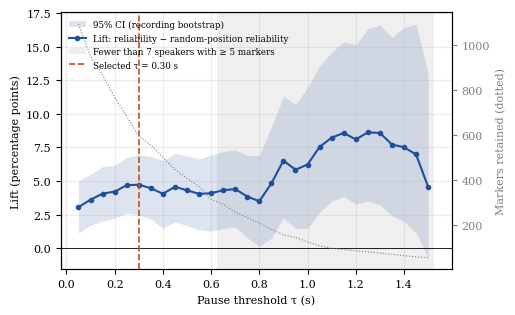

τ used for pause formatting and the LLM stage: 0.3 s (auto; manual value 0.7)
[threshold selection] RAM 3.7/31.3 GB (13%) | run folder 6.4 MB | free disk 19.5 GB | GPU 0.00 GB (peak 0.00) / 14.6 GB


In [10]:
# 5.0  Pause-threshold selection
def norm_del(t):     
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9'\s]", "", str(t).upper())).strip()

def norm_space(t):   
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9'\s]", " ", str(t).upper())).strip()

def find_asr_errors(ref, hyp):
    n, m = len(ref), len(hyp)
    dp = np.zeros((n + 1, m + 1), dtype=int); dp[:, 0] = np.arange(n + 1); dp[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            dp[i, j] = dp[i-1, j-1] if ref[i-1] == hyp[j-1] else 1 + min(dp[i-1, j-1], dp[i-1, j], dp[i, j-1])
    i, j, tokens, deletions = n, m, set(), set()
    while i > 0 or j > 0:
        if i > 0 and j > 0 and ref[i-1] == hyp[j-1] and dp[i, j] == dp[i-1, j-1]: i -= 1; j -= 1
        elif i > 0 and j > 0 and dp[i, j] == dp[i-1, j-1] + 1: tokens.add(j - 1); i -= 1; j -= 1
        elif i > 0 and dp[i, j] == dp[i-1, j] + 1: deletions.add((i - 1, j)); i -= 1
        else: tokens.add(j - 1); j -= 1
    return tokens, deletions

def errors_near(boundary, tokens, deletions, window):
    near = {("t", t) for t in tokens if boundary - window <= t <= boundary + window - 1}
    near |= {("d", r, d) for r, d in deletions if abs(d - boundary) <= window}
    return near


def boundary_table(frame, window=2):
    rows = []
    for r in frame.itertuples():
        if not isinstance(r.ctc_json, str): continue
        ref = norm_del(r.transcription).split()
        if not ref: continue
        ctc = json.loads(r.ctc_json); hyp, gap_at = [], {}
        for i, it in enumerate(ctc):
            hyp.extend(norm_del(it["word"]).split())
            if i < len(ctc) - 1:
                gap_at[len(hyp)] = max(gap_at.get(len(hyp), 0.0), float(it.get("pause_after") or 0))
        if len(hyp) < 2: continue
        tok, dele = find_asr_errors(ref, hyp)
        for b in range(1, len(hyp)):
            rows.append((r.sample_id, r.speaker, r.speech_status, r.split, r.recording, r.mic, b,
                         gap_at.get(b, 0.0), bool(errors_near(b, tok, dele, window))))
    return pd.DataFrame(rows, columns=["sample_id", "speaker", "status", "split", "recording", "mic", "b", "gap", "y"])

def lift_curve(d):
    n_spk, rows = d.speaker.nunique(), []
    for t in C.TUNE_GRID:
        s = d[d.gap >= t]
        if not len(s): continue
        per = s.groupby("speaker").size()
        n_ok = int((per >= C.MIN_MARKERS_PER_SPEAKER).sum())
        rows.append(dict(tau=t, markers=len(s), utterances=s.sample_id.nunique(), speakers_with_min=n_ok,
                         top2_speaker_share=per.nlargest(2).sum() / len(s), reliability=s.y.mean(),
                         random_reliability=s.chance.mean(), lift=s.y.mean() - s.chance.mean(),
                         supported=n_ok >= n_spk - 1))
    return pd.DataFrame(rows)

def select_tau(d):
    T = lift_curve(d)
    T = T[T.supported] if len(T) else T
    return None if T.empty else float(T.loc[T.lift.idxmax(), "tau"])

def perm_p(sel, pool, n=2000, seed=C.SEED):
    rng = np.random.default_rng(seed)
    groups = {u: g.y.values for u, g in pool.groupby("sample_id")}
    cnt, rel = sel.groupby("sample_id").size(), sel.y.mean()
    perm = [sum(rng.choice(groups[u], size=min(k, len(groups[u])), replace=False).sum() for u, k in cnt.items()) / cnt.sum()
            for _ in range(n)]
    return (np.sum(np.array(perm) >= rel) + 1) / (n + 1)

bnd = boundary_table(meta[["sample_id", "transcription", "speech_status", "split", "speaker", "recording", "mic"]]
                     .merge(ctc_df, on="sample_id"))
dys_b = bnd[bnd.status == "dysarthria"].copy()
dys_b["chance"] = dys_b.groupby("sample_id").y.transform("mean")
print(f"boundaries: {len(bnd):,} (dysarthric {len(dys_b):,}) | dysarthric speakers: {dys_b.speaker.nunique()}")

tau_manual, selected = C.TAU, (select_tau(dys_b) if dys_b.speaker.nunique() >= 3 else None)
curve = lift_curve(dys_b) if len(dys_b) else pd.DataFrame()
sel_report = {"tau_manual": tau_manual, "tau_selected": selected}

if selected is not None:
    # recording-level bootstrap CI of the lift (both microphones of a recording are resampled together)
    rng = np.random.default_rng(C.SEED)
    recs = dys_b.recording.unique(); ri = dys_b.recording.map({r: i for i, r in enumerate(recs)}).values
    draws = rng.integers(0, len(recs), size=(2000, len(recs)))
    boot = {}
    for t in curve.tau:
        m = (dys_b.gap >= t).values
        h = np.bincount(ri[m], weights=dys_b.y.values[m].astype(float), minlength=len(recs))
        c = np.bincount(ri[m], weights=dys_b.chance.values[m], minlength=len(recs))
        k = np.bincount(ri[m], minlength=len(recs)).astype(float)
        boot[t] = (h[draws].sum(1) - c[draws].sum(1)) / np.maximum(k[draws].sum(1), 1)
    curve["lift_ci_low"] = [np.percentile(boot[t], 2.5) for t in curve.tau]
    curve["lift_ci_high"] = [np.percentile(boot[t], 97.5) for t in curve.tau]
    diffs = []
    for other in sorted({tau_manual, 0.1, 1.1} - {selected}):
        if other in boot:
            d_ = boot[selected] - boot[other]
            diffs.append({"tau_a": selected, "tau_b": other, "lift_diff": float(np.mean(d_)),
                          "ci_low": float(np.percentile(d_, 2.5)), "ci_high": float(np.percentile(d_, 97.5))})
    # leave-one-speaker-out
    held, picks = [], []
    for s in sorted(dys_b.speaker.unique()):
        t = select_tau(dys_b[dys_b.speaker != s]); picks.append({"held_out_speaker": s, "tau_selected_on_others": t})
        if t is not None: held.append(dys_b[(dys_b.speaker == s) & (dys_b.gap >= t)].assign(fold=s))
    H = pd.concat(held)
    loso = pd.DataFrame(picks).merge(H.groupby("fold").apply(lambda g: pd.Series(
        {"heldout_markers": len(g), "heldout_lift": g.y.mean() - g.chance.mean()})).reset_index()
        .rename(columns={"fold": "held_out_speaker"}), on="held_out_speaker", how="left")
    sel_report.update({"loso_heldout_markers": len(H), "loso_heldout_reliability": H.y.mean(),
                       "loso_heldout_random": H.chance.mean(), "loso_heldout_lift": H.y.mean() - H.chance.mean(),
                       "loso_perm_p": perm_p(H, dys_b), "lift_differences": diffs})
    # robustness: selected vs manual tau on subsets
    one_mic = dys_b.sort_values("mic", key=lambda s: s.ne("headMic")).drop_duplicates(["recording", "b"])
    rob = []
    for t in sorted({selected, tau_manual}):
        for label, d_ in [("all dysarthric", dys_b), ("one mic per recording", one_mic),
                          ("test split", dys_b[dys_b.split == "test"]), ("train+val", dys_b[dys_b.split.isin(["train", "val"])])]:
            s_ = d_[d_.gap >= t]
            if len(s_):
                rob.append({"tau": t, "set": label, "markers": len(s_), "reliability": s_.y.mean(), "random_reliability": s_.chance.mean(),
                            "lift": s_.y.mean() - s_.chance.mean(), "perm_p": perm_p(s_, dys_b)})
    rob = pd.DataFrame(rob)
    curve.to_csv(os.path.join(C.TABLE_DIR, "threshold_selection_curve.csv"), index=False)
    loso.to_csv(os.path.join(C.TABLE_DIR, "threshold_selection_loso.csv"), index=False)
    rob.to_csv(os.path.join(C.TABLE_DIR, "threshold_selection_robustness.csv"), index=False)
    pd.DataFrame(diffs).to_csv(os.path.join(C.TABLE_DIR, "threshold_selection_differences.csv"), index=False)

    show = curve[["tau", "markers", "speakers_with_min", "top2_speaker_share", "reliability", "random_reliability", "lift", "lift_ci_low", "lift_ci_high", "supported"]].copy()
    for col in ["top2_speaker_share", "reliability", "random_reliability", "lift", "lift_ci_low", "lift_ci_high"]: show[col] = (100 * show[col]).round(2)
    print(show.to_string(index=False))
    print("\nLOSO:"); print(loso.round(3).to_string(index=False))
    print(f"LOSO pooled held-out: markers={len(H)}, lift={100*(H.y.mean()-H.chance.mean()):.2f} pts, p={sel_report['loso_perm_p']:.4f}")
    print("\nDifferences in lift:", json.dumps(diffs, indent=1))
    print("\nRobustness:"); print(rob.round(4).to_string(index=False))

    # figure (candidate replacement for Fig. 2)
    plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"], "font.size": 8})
    fig, ax = plt.subplots(figsize=(5.2, 3.2))
    ax.fill_between(curve.tau, 100 * curve.lift_ci_low, 100 * curve.lift_ci_high, color="#1f4e9c", alpha=.15, lw=0, label="95% CI (recording bootstrap)")
    ax.plot(curve.tau, 100 * curve.lift, "o-", color="#1f4e9c", ms=3, lw=1.5, label="Lift: reliability − random-position reliability")
    uns = curve[~curve.supported]
    if len(uns): ax.axvspan(uns.tau.min() - 0.025, curve.tau.max() + 0.025, color="gray", alpha=.12, lw=0,
                            label=f"Fewer than {dys_b.speaker.nunique() - 1} speakers with ≥ {C.MIN_MARKERS_PER_SPEAKER} markers")
    ax.axhline(0, color="black", lw=.6); ax.axvline(selected, ls="--", color="#c0501f", lw=1.2, label=f"Selected τ = {selected:.2f} s")
    ax.set_xlabel("Pause threshold τ (s)"); ax.set_ylabel("Lift (percentage points)"); ax.grid(alpha=.25)
    ax.legend(fontsize=6.3, frameon=False, loc="upper left")
    ax2 = ax.twinx(); ax2.plot(curve.tau, curve.markers, color="gray", lw=.8, ls=":")
    ax2.set_ylabel("Markers retained (dotted)", color="gray"); ax2.tick_params(axis="y", colors="gray")
    fig.tight_layout()
    fig.savefig(os.path.join(C.OUT_DIR, "fig_threshold_selection.pdf")); fig.savefig(os.path.join(C.OUT_DIR, "fig_threshold_selection.png"), dpi=200)
    plt.show()

if C.TAU_SELECTION == "auto":
    if selected is None:
        print(f"No eligible threshold (too little data, e.g. smoke test): keeping the manual TAU = {C.TAU}")
    else:
        C.TAU = selected
print(f"τ used for pause formatting and the LLM stage: {C.TAU} s ({C.TAU_SELECTION}; manual value {tau_manual})")
with open(os.path.join(C.OUT_DIR, "threshold_selection.json"), "w") as f:
    json.dump(sel_report, f, indent=2, default=float)
write_manifest({"tau_selection": sel_report})
resource_report("threshold selection")


## 5. Pause formatting
Identical to the original formatter: a marker `[x.xs_pause]` is inserted after a word whose following gap is at least the threshold, plus (in `reproduce` mode) a marker for leading silence. The `CANDIDATE_THRESHOLD` column defines the threshold-analysis set (589 utterances in the paper) and the `TAU` column defines the utterances sent to the LLM (183 in the paper).

In [11]:
def format_pause_aware_transcript(ctc_result, pause_threshold, leading=True):
    out = []
    for index, item in enumerate(ctc_result):
        if index == 0 and leading:
            start_pause = item.get("start", 0.0) or 0.0
            if start_pause >= pause_threshold:
                out.append(f"[{start_pause:.1f}s_pause]")
        out.append(item["word"])
        pause_after = item.get("pause_after", 0.0) or 0.0
        if pause_after >= pause_threshold:
            out.append(f"[{pause_after:.1f}s_pause]")
    return " ".join(out)

BETWEEN_RE = re.compile(r"\S+\s+\[\d+(?:\.\d+)?s_pause\]\s+\S+")

df = (meta[["sample_id", "audio_name", "transcription", "speech_status", "split", "speaker", "mic", "recording"]]
      .rename(columns={"transcription": "actual_truth"})
      .merge(asr_ft, on="sample_id").merge(ctc_df, on="sample_id"))
df["ctc_result"] = df.ctc_json.map(lambda s: json.loads(s) if isinstance(s, str) else [])

thresholds = sorted(set(C.FORMAT_THRESHOLDS) | {C.CANDIDATE_THRESHOLD, C.TAU})
counts = []
for t in thresholds:
    col = f"pause_threshold:{t}"
    df[col] = df.ctc_result.map(lambda r: format_pause_aware_transcript(r, t, C.LEADING_MARKER))
    counts.append({"threshold": t, "with_any_marker": int(df[col].str.contains("s_pause]", regex=False).sum()),
                   "with_between_word_marker": int(df[col].str.contains(BETWEEN_RE).sum())})
counts = pd.DataFrame(counts)
counts.to_csv(os.path.join(C.TABLE_DIR, "pause_marker_counts.csv"), index=False)
print(counts.to_string(index=False))

df["in_candidate_set"] = df[f"pause_threshold:{C.CANDIDATE_THRESHOLD}"].str.contains(BETWEEN_RE)
df["in_llm_set"] = df[f"pause_threshold:{C.TAU}"].str.contains(BETWEEN_RE)
print(f"Threshold-analysis set: {df.in_candidate_set.sum()} utterances (paper: 589)")
print(f"LLM set at τ={C.TAU}: {df.in_llm_set.sum()} utterances (paper: 183)")
save_stage(df.drop(columns=["ctc_result"]), "pauses")
resource_report("pauses")

 threshold  with_any_marker  with_between_word_marker
      0.02              570                       570
      0.10              505                       505
      0.20              441                       441
      0.30              365                       365
      0.40              327                       327
      0.50              277                       277
      0.60              216                       216
      0.70              175                       175
      0.80              146                       146
Threshold-analysis set: 570 utterances (paper: 589)
LLM set at τ=0.3: 365 utterances (paper: 183)
pauses: 16,552 rows → /kaggle/working/torgo_pause_eval_fixed/checkpoints/pauses.parquet


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

 backed up to hf.co/datasets/Menhaz/torgo-pause-eval-fixed
[pauses] RAM 3.2/31.3 GB (12%) | run folder 6.4 MB | free disk 19.5 GB | GPU 0.00 GB (peak 0.00) / 14.6 GB


## 6. Threshold analysis with a random-position baseline
Reliability, marker coverage and error coverage are computed exactly as in `reasoning-for-threshold.ipynb`. Added here: the **random-position baseline** (markers moved to random word boundaries of the same utterance, 2,000 permutations), the same analysis without duplicate microphone channels, on the test split only, per speaker group, and the utterance-level association.

In [12]:
# (norm_del, norm_space, find_asr_errors, errors_near are defined in stage 5.0)
def words_and_pauses(ctc_result):
    words, pauses = [], []
    for i, item in enumerate(ctc_result):
        words.extend(norm_del(item["word"]).split())
        if i < len(ctc_result) - 1:
            p = float(item.get("pause_after") or 0)
            if p > 0: pauses.append((p, len(words)))
    return words, pauses

utts = []
for rid, row in df[df.in_candidate_set].iterrows():
    ref = norm_del(row.actual_truth).split()
    hyp, pauses = words_and_pauses(row.ctc_result)
    tok, dele = find_asr_errors(ref, hyp)
    errors = {(rid, "t", t) for t in tok} | {(rid, "d") + d for d in dele}
    bnear = {b: {(rid,) + e for e in errors_near(b, tok, dele, C.WINDOW)} for b in range(1, len(hyp))}
    utts.append(dict(rid=rid, split=row.split, status=row.speech_status, speaker=row.speaker, mic=row.mic,
                     recording=row.recording, errors=errors, pauses=pauses, bnear=bnear, nb=len(hyp) - 1))
print(f"pause events: {sum(len(u['pauses']) for u in utts)} (paper 1,259) | ASR errors: {len(set().union(*[u['errors'] for u in utts])) if utts else 0} (paper 1,660)")

def threshold_table(us, label):
    rng = np.random.default_rng(C.SEED)
    errs = set().union(*[u["errors"] for u in us]) if us else set()
    rows = []
    for t in C.SWEEP:
        sel = [(u, b) for u in us for (d, b) in u["pauses"] if d >= t]
        if not sel or not errs: continue
        rel = np.mean([len(u["bnear"].get(b, set())) > 0 for u, b in sel])
        cov = len(set().union(*[u["bnear"].get(b, set()) for u, b in sel])) / len(errs)
        chance = np.mean([np.mean([len(s) > 0 for s in u["bnear"].values()]) for u, _ in sel])
        per_utt = {}
        for u, _ in sel: per_utt[u["rid"]] = (u, per_utt.get(u["rid"], (u, 0))[1] + 1)
        perm_rel, perm_cov = [], []
        for _ in range(C.N_PERM):
            hits = total = 0; covered = set()
            for u, k in per_utt.values():
                for b in rng.choice(np.arange(1, u["nb"] + 1), size=min(k, u["nb"]), replace=False):
                    s = u["bnear"][b]; hits += len(s) > 0; total += 1; covered |= s
            perm_rel.append(hits / total); perm_cov.append(len(covered) / len(errs))
        rows.append({"set": label, "threshold": t, "markers": len(sel), "reliability": rel, "random_reliability": chance,
                     "p_value": (np.sum(np.array(perm_rel) >= rel) + 1) / (C.N_PERM + 1),
                     "marker_coverage": len(sel) / max(sum(len(u["pauses"]) for u in us), 1),
                     "error_coverage": cov, "random_error_coverage": float(np.mean(perm_cov)),
                     "n_utterances": len(us), "n_errors": len(errs)})
    return pd.DataFrame(rows)

dedup, seen = [], set()
for u in sorted(utts, key=lambda u: 0 if u["mic"] == "headMic" else 1):
    if u["recording"] not in seen: seen.add(u["recording"]); dedup.append(u)

tables = [threshold_table(utts, "all"),
          threshold_table([u for u in utts if u["status"] == "dysarthria"], "dysarthric"),
          threshold_table([u for u in utts if u["status"] == "healthy"], "healthy"),
          threshold_table([u for u in utts if u["split"] == "test"], "test_split"),
          threshold_table(dedup, "one_mic_per_recording")]
thr_all = pd.concat(tables, ignore_index=True)
thr_all.to_csv(os.path.join(C.TABLE_DIR, "threshold_analysis_all_sets.csv"), index=False)

# Table 2 of the revised paper: "all" set + p-value after removing duplicate microphones
t2 = thr_all[thr_all.set == "all"].merge(
    thr_all[thr_all.set == "one_mic_per_recording"][["threshold", "p_value"]].rename(columns={"p_value": "p_value_one_mic"}),
    on="threshold", how="left")
t2.to_csv(os.path.join(C.TABLE_DIR, "table2_threshold.csv"), index=False)
show = t2[["threshold", "markers", "reliability", "random_reliability", "p_value", "p_value_one_mic", "error_coverage", "random_error_coverage"]].copy()
for c in ["reliability", "random_reliability", "error_coverage", "random_error_coverage"]: show[c] = (100 * show[c]).round(2)
print(show.to_string(index=False))

pause events: 1218 (paper 1,259) | ASR errors: 1617 (paper 1,660)
 threshold  markers  reliability  random_reliability  p_value  p_value_one_mic  error_coverage  random_error_coverage
       0.1      962        67.57               63.68 0.000500         0.000500           63.88                  60.96
       0.2      773        69.86               65.47 0.000500         0.000500           56.77                  53.09
       0.3      599        71.79               67.03 0.000500         0.001000           46.75                  44.42
       0.4      504        70.44               66.35 0.000500         0.009995           40.32                  38.39
       0.5      411        72.26               67.89 0.001999         0.006497           34.94                  33.11
       0.6      317        75.71               71.58 0.004998         0.042479           28.26                  27.45
       0.7      260        77.69               73.25 0.005497         0.074463           23.56              

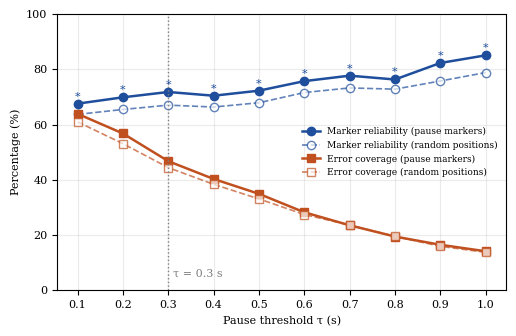

In [13]:
# 6.1  Fig. 2 (revised): pause markers vs random positions
if len(t2):
    plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"], "font.size": 8})
    fig, ax = plt.subplots(figsize=(5.2, 3.4))
    ax.plot(t2.threshold, 100 * t2.reliability, "o-", color="#1f4e9c", lw=1.8, label="Marker reliability (pause markers)")
    ax.plot(t2.threshold, 100 * t2.random_reliability, "o--", color="#1f4e9c", lw=1.2, alpha=.7, mfc="white", label="Marker reliability (random positions)")
    ax.plot(t2.threshold, 100 * t2.error_coverage, "s-", color="#c0501f", lw=1.8, label="Error coverage (pause markers)")
    ax.plot(t2.threshold, 100 * t2.random_error_coverage, "s--", color="#c0501f", lw=1.2, alpha=.7, mfc="white", label="Error coverage (random positions)")
    ax.axvline(C.TAU, ls=":", color="gray", lw=1); ax.text(C.TAU + 0.01, 5, f"τ = {C.TAU} s", color="gray")
    for t, rel, pv in zip(t2.threshold, t2.reliability, t2.p_value):
        if pv < 0.05: ax.annotate("*", (t, 100 * rel + 1.5), ha="center", color="#1f4e9c")
    ax.set_xlabel("Pause threshold τ (s)"); ax.set_ylabel("Percentage (%)"); ax.set_xticks(list(t2.threshold)); ax.set_ylim(0, 100)
    ax.grid(alpha=.25); ax.legend(loc="center right", fontsize=6.5, frameon=False)
    fig.tight_layout()
    fig.savefig(os.path.join(C.OUT_DIR, "fig2_threshold_vs_random.pdf")); fig.savefig(os.path.join(C.OUT_DIR, "fig2_threshold_vs_random.png"), dpi=200)
    plt.show()

In [14]:
# 6.2  Utterance-level association: do pauses flag WHICH utterances contain errors?
mw = df[df.actual_truth.fillna("").map(lambda x: len(norm_del(x).split()) >= 2)].copy()
mw["max_gap"] = mw.ctc_result.map(lambda r: max([(it.get("pause_after") or 0) for it in r[:-1]], default=0))
ops = [jiwer.process_words(norm_del(r), norm_del(h) or "X") for r, h in zip(mw.actual_truth, mw.asr_transcription)]
mw["n_err"] = [o.substitutions + o.deletions + o.insertions for o in ops]
mw["n_ref"] = [o.hits + o.substitutions + o.deletions for o in ops]
mw["has_err"], mw["flagged"] = mw.n_err > 0, mw.max_gap >= C.TAU

rows = []
for name, d in [("all multi-word", mw), ("dysarthric", mw[mw.speech_status == "dysarthria"]),
                ("dysarthric, test split", mw[(mw.speech_status == "dysarthria") & (mw.split == "test")])]:
    a, b = d[d.flagged], d[~d.flagged]
    within = [roc_auc_score(g.has_err, g.max_gap) for _, g in d.groupby("speaker") if g.has_err.nunique() == 2 and len(g) >= 20]
    rows.append({"set": name, "n": len(d), "flagged": len(a),
                 "wer_flagged": a.n_err.sum() / max(a.n_ref.sum(), 1), "wer_unflagged": b.n_err.sum() / max(b.n_ref.sum(), 1),
                 "p_err_flagged": a.has_err.mean() if len(a) else np.nan, "p_err_unflagged": b.has_err.mean() if len(b) else np.nan,
                 "auroc_pooled": roc_auc_score(d.has_err, d.max_gap) if d.has_err.nunique() == 2 else np.nan,
                 "auroc_within_speaker_mean": float(np.mean(within)) if within else np.nan})
utt_level = pd.DataFrame(rows)
utt_level.to_csv(os.path.join(C.TABLE_DIR, "utterance_level_association.csv"), index=False)
print(utt_level.round(3).to_string(index=False))
resource_report("threshold analysis")

                   set    n  flagged  wer_flagged  wer_unflagged  p_err_flagged  p_err_unflagged  auroc_pooled  auroc_within_speaker_mean
        all multi-word 4162      359        0.364          0.128          0.799            0.265         0.646                      0.549
            dysarthric 1321      356        0.360          0.316          0.798            0.499         0.669                      0.571
dysarthric, test split  143       36        0.452          0.214          0.806            0.533         0.687                      0.447
[threshold analysis] RAM 3.2/31.3 GB (12%) | run folder 6.4 MB | free disk 19.5 GB | GPU 0.00 GB (peak 0.00) / 14.6 GB


## 7. LLM correction of pause regions
Same logic as `llm-pause-inference.ipynb`: ±4-word regions around every marker, gpt-oss-120b on Groq, an edit-distance guard (≤2 words and ≤40%), and regions substituted back into the sentence. Every response is appended to `llm_jobs_<condition>.jsonl` immediately, so an interrupted run (e.g., after a Groq rate limit) continues where it stopped.

Conditions: `pause` (the paper) and, if `RUN_CONTROLS=True`, `no_marker` (same regions, markers removed) and `random_marker` (same number of markers placed at random word boundaries). The controls show whether the *markers* help, which the paper cannot claim without them.

In [15]:
PROMPT_EXAMPLES = {

    "original": "QUISH -> QUICK\nWASH WASH -> WASH\nSNOWISH -> SNOW",

    "neutral": "KITCHUN -> KITCHEN\nBLUE BLUE -> BLUE\nSPOONFULISH -> SPOONFUL",
}

SYSTEM_PROMPT = """
You are a conservative ASR transcription error-correction system for
dysarthric speech.

The input is a SHORT LOCAL ASR segment containing pause markers such as
[0.7s_pause].

Pause markers represent acoustic silence and are only POSSIBLE cues for
an ASR recognition error. A pause does NOT mean an error definitely exists.

Your goal is to recover obvious ASR recognition errors, NOT to rewrite,
polish, or improve the sentence.

DEFAULT ACTION:
KEEP THE INPUT UNCHANGED.

Make a correction only when there is strong evidence that a specific
token is an ASR recognition error.

HIGH-CONFIDENCE corrections include:

- an obviously malformed or corrupted word,
- an obvious phonetic near-miss,
- an accidentally repeated word,
- an obviously missing word,
- an obviously spurious extra word.

Examples of the type of correction that may be appropriate:

{examples}

STRICT RULES:

1. Prefer NO CHANGE whenever uncertain.

2. A pause marker alone is NOT evidence that a word is wrong.

3. Do NOT modify a correctly formed, contextually plausible word unless
   there is strong evidence that the word itself is an ASR recognition
   error.

4. Do NOT replace one plausible English word with another plausible
   English word based only on semantic or grammatical preference.

5. Do NOT paraphrase or use synonyms.

6. Do NOT perform general grammar correction.

7. Do NOT change tense, number, agreement, contractions, or word form
   merely to make the sentence grammatical.

8. Do NOT insert or delete function words such as:
   a, an, the, to, of, my, his, her, in, on, than, and
   merely to improve grammar or fluency.

   Change a function word only when there is strong local evidence
   that the function word itself was inserted, omitted, or
   misrecognized by ASR.

9. Do NOT change the spelling or form of a valid word unless there is
   strong evidence that the original token itself is an ASR
   recognition error.

10. Do NOT change a word because another possibly erroneous ASR word
    makes the phrase sound grammatically strange. The other word may
    itself be the recognition error.

11. Make the smallest possible correction.

12. Focus corrections on words close to the pause marker.

13. Preserve pause markers exactly as written when they appear.

14. If there is no obvious high-confidence ASR error, return the input
    unchanged.

Before every change, ask:

"Is the original token clearly more likely to be an ASR recognition
error than a valid spoken word?"

If the answer is not clearly YES, do not change it.

Return ONLY the resulting segment.
Do not provide explanations, labels, JSON, markdown, or alternatives.
""".replace("{examples}", PROMPT_EXAMPLES[C.PROMPT_EXAMPLES])

PAUSE_RE = re.compile(r"^\[\d+(?:\.\d+)?s_pause\]$", re.IGNORECASE)
def is_pause(token): return bool(PAUSE_RE.fullmatch(token))
def remove_pause_markers(text): return " ".join(t for t in str(text).split() if not is_pause(t))
def normalize_words(text): return re.sub(r"[^A-Z0-9'\s]", "", str(text).upper()).split()

def extract_pause_regions(text, k):
    tokens = str(text).split(); n = len(tokens)
    selected = [False] * n
    for p in [i for i, t in enumerate(tokens) if is_pause(t)]:
        selected[p] = True
        for step in (-1, 1):
            seen, i = 0, p + step
            while 0 <= i < n and seen < k:
                selected[i] = True
                if not is_pause(tokens[i]): seen += 1
                i += step
    regions, i = [], 0
    while i < n:
        if not selected[i]: i += 1; continue
        start = i
        while i < n and selected[i]: i += 1
        regions.append({"start": start, "end": i - 1, "input_region": " ".join(tokens[start:i])})
    return regions

def word_edit_distance(a, b):
    a, b = normalize_words(remove_pause_markers(a)), normalize_words(remove_pause_markers(b))
    prev = list(range(len(b) + 1))
    for i, wa in enumerate(a, 1):
        cur = [i]
        for j, wb in enumerate(b, 1):
            cur.append(min(prev[j - 1] + (wa != wb), prev[j] + 1, cur[j - 1] + 1))
        prev = cur
    return prev[-1]

def clean_llm_output(text):
    if text is None: return None
    text = re.sub(r"^```(?:text)?", "", str(text).strip(), flags=re.IGNORECASE)
    text = re.sub(r"```$", "", text).strip()
    text = re.sub(r"^(corrected|output|corrected segment)\s*:\s*", "", text, flags=re.IGNORECASE)
    return text.strip("\"' ")

def validate_llm_output(original, candidate):
    if candidate is None: return original, "llm_failure"
    candidate = clean_llm_output(candidate)
    if not candidate: return original, "empty_output"
    dist = word_edit_distance(original, candidate)
    if dist > C.MAX_ABS_EDITS or dist / max(len(normalize_words(remove_pause_markers(original))), 1) > C.MAX_EDIT_RATIO:
        return original, "excessive_rewrite"
    return candidate, "accepted"

def reconstruct_sentence(formatted_text, jobs):
    tokens = str(formatted_text).split()
    for job in sorted(jobs, key=lambda j: j["start"], reverse=True):
        tokens[job["start"]:job["end"] + 1] = str(job["accepted_output"]).split()
    return " ".join(tokens)

def response_text(response):
    content = response.content
    if isinstance(content, list):
        content = " ".join(str(c.get("text", "")) if isinstance(c, dict) else str(c) for c in content)
    return str(content).strip()

In [16]:
# 7.1  LLM client
from langchain_core.messages import SystemMessage, HumanMessage

class EchoLLM:
    """Test double: returns the segment unchanged (no API calls)."""
    class _R:
        def __init__(self, c): self.content = c
    def _one(self, msgs): return self._R(msgs[-1].content.split("\n\n", 1)[1])
    def invoke(self, msgs): return self._one(msgs)
    def batch(self, many, config=None, return_exceptions=True): return [self._one(m) for m in many]

def build_llm():
    if C.LLM_BACKEND == "fake":
        print("Using EchoLLM (no API calls)"); return EchoLLM()
    key = get_secret("GROQ_API_KEY") or get_secret("R_GROQ_API_KEY")
    if not key:
        raise RuntimeError("GROQ_API_KEY secret not found: add it in Add-ons → Secrets, or set RUN_LLM=False")
    from langchain_groq import ChatGroq
    return ChatGroq(model=C.LLM_MODEL, api_key=key, temperature=C.LLM_TEMPERATURE)

def make_messages(segment):
    return [SystemMessage(content=SYSTEM_PROMPT), HumanMessage(content="Correct the following local ASR segment.\n\n" + segment)]

DAILY_LIMIT_MARKERS = ("tokens per day", "(TPD)", "requests per day", "(RPD)")
BACKUP_EVERY_N_BATCHES = 5          # push the JSONL to HF every 5 batches (40 calls), so answers survive a crash

def is_daily_limit(err):
    return bool(err) and any(k in err for k in DAILY_LIMIT_MARKERS)

def run_llm_jobs(llm, jobs, condition):
    """Runs pending jobs; every answer is appended to a JSONL checkpoint immediately and backed up regularly.
    Stops at the first daily-limit error: retrying cannot succeed until the provider's quota resets."""
    path = os.path.join(C.CKPT_DIR, f"llm_jobs_{condition}_tau{C.TAU:g}.jsonl")
    done = {}
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            for line in f:
                rec = json.loads(line); done[rec["job_key"]] = rec
    pending = [j for j in jobs if j["job_key"] not in done or done[j["job_key"]]["raw_llm_output"] is None]
    print(f"[{condition}] jobs: {len(jobs)} | already done: {len(jobs) - len(pending)} | to run: {len(pending)}")
    stop_reason = None
    with open(path, "a", encoding="utf-8") as f:
        for n_batch, s in enumerate(tqdm(range(0, len(pending), C.LLM_BATCH), desc=f"LLM {condition}")):
            batch = pending[s:s + C.LLM_BATCH]
            msgs = [make_messages(j["input_region"]) for j in batch]
            try:
                responses = llm.batch(msgs, config={"max_concurrency": C.LLM_CONCURRENCY}, return_exceptions=True)
            except Exception as e:
                responses = [e] * len(batch)
            for j, m, r in zip(batch, msgs, responses):
                text, err = None, None
                if isinstance(r, Exception):
                    err = str(r)[:300]
                    if not is_daily_limit(err):
                        for attempt in range(C.LLM_RETRIES):
                            try:
                                text, err = response_text(llm.invoke(m)), None; break
                            except Exception as e:
                                err = str(e)[:300]
                                if is_daily_limit(err): break
                                time.sleep(2 * 2 ** attempt)
                else:
                    text = response_text(r)
                rec = {**j, "raw_llm_output": text, "llm_error": err}
                done[j["job_key"]] = rec
                f.write(json.dumps(rec) + "\n"); f.flush(); os.fsync(f.fileno())
                if is_daily_limit(err): stop_reason = err
            if (n_batch + 1) % BACKUP_EVERY_N_BATCHES == 0:
                backup_to_hf()
            if stop_reason:
                print(f"Provider daily limit reached; stopping now (no point retrying until it resets).\n   {stop_reason}")
                break
    backup_to_hf()       # always save what arrived, including on the way to the failure guard below
    n_ok = sum(1 for j in jobs if (done.get(j["job_key"]) or {}).get("raw_llm_output") is not None)
    print(f"[{condition}] answered: {n_ok}/{len(jobs)} (saved in {os.path.basename(path)})")
    return [done.get(j["job_key"], {**j, "raw_llm_output": None, "llm_error": stop_reason or "not run"}) for j in jobs]

In [17]:
# 7.2  Build jobs per condition, run, validate, reconstruct
def random_marker_text(row, rng):
    """Same words and the same marker durations as the τ-formatted text, markers moved to random word boundaries."""
    toks = row[f"pause_threshold:{C.TAU}"].split()
    lead = toks[0] if toks and is_pause(toks[0]) else None
    body = toks[1:] if lead else toks
    words = [t for t in body if not is_pause(t)]
    markers = [t for t in body if is_pause(t)]
    k = min(len(markers), max(len(words) - 1, 0))
    positions = set(rng.choice(np.arange(1, len(words)), size=k, replace=False).tolist()) if k else set()
    out, mi = ([lead] if lead else []), 0
    for i, w in enumerate(words, 1):
        out.append(w)
        if i in positions: out.append(markers[mi]); mi += 1
    return " ".join(out)

def build_condition_text(sel, condition):
    rng = np.random.default_rng(C.SEED)
    if condition == "random_marker":
        return [random_marker_text(r, rng) for _, r in sel.iterrows()]
    return sel[f"pause_threshold:{C.TAU}"].tolist()

def build_jobs(sel, texts, condition):
    jobs = []
    for (_, row), text in zip(sel.iterrows(), texts):
        for rid, reg in enumerate(extract_pause_regions(text, C.LLM_K)):
            region = remove_pause_markers(reg["input_region"]) if condition == "no_marker" else reg["input_region"]
            if not region.strip(): continue
            jobs.append({"job_key": f"{condition}|{int(row.sample_id)}|{rid}", "sample_id": int(row.sample_id),
                         "region_id": rid, "start": reg["start"], "end": reg["end"], "input_region": region})
    return jobs

def wer_details(reference, hypothesis):
    """Verbatim logic of the original notebook (keeps its S/D/I tie-breaking, so Table 3 reproduces exactly)."""
    ref, hyp = normalize_words(reference), normalize_words(hypothesis)
    n, m = len(ref), len(hyp)
    dp = np.zeros((n + 1, m + 1), dtype=int); back = np.empty((n + 1, m + 1), dtype=object)
    for i in range(1, n + 1): dp[i, 0], back[i, 0] = i, "D"
    for j in range(1, m + 1): dp[0, j], back[0, j] = j, "I"
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            if ref[i - 1] == hyp[j - 1]:
                dp[i, j], back[i, j] = dp[i - 1, j - 1], "C"
            else:
                dp[i, j], back[i, j] = min([(dp[i-1, j-1] + 1, "S"), (dp[i-1, j] + 1, "D"), (dp[i, j-1] + 1, "I")], key=lambda x: x[0])
    i, j, S, D, I = n, m, 0, 0, 0
    while i > 0 or j > 0:
        op = back[i, j]
        if op == "C": i -= 1; j -= 1
        elif op == "S": S += 1; i -= 1; j -= 1
        elif op == "D": D += 1; i -= 1
        elif op == "I": I += 1; j -= 1
        else: break
    return {"S": S, "D": D, "I": I, "errors": S + D + I, "N": n, "wer": (S + D + I) / n if n else np.nan}

LLM_RESULTS = {}
if C.RUN_LLM:
    sel = df[df.in_llm_set].copy()
    conditions = ["pause"] + (["no_marker", "random_marker"] if C.RUN_CONTROLS else [])
    llm = None
    for cond in conditions:
        stage = f"llm_results_{cond}_tau{C.TAU:g}"
        res = load_stage(stage)
        if res is not None:
            print(f"{stage}: loaded from checkpoint (delete {ckpt_path(stage)} to re-validate from the JSONL)")
            LLM_RESULTS[cond] = res; continue
        llm = llm or build_llm()
        texts = build_condition_text(sel, cond)
        answered = run_llm_jobs(llm, build_jobs(sel, texts, cond), cond)
        failed = [r for r in answered if r["raw_llm_output"] is None]
        if failed:
            # do NOT save llm_results_*: a failed call would silently count as "unchanged" in Table 3
            raise RuntimeError(f"[{cond}] {len(failed)} of {len(answered)} LLM calls failed (last error: {failed[-1]['llm_error']}). "
                               "Successful answers are kept in the JSONL checkpoint; re-run this cell (e.g. after the Groq "
                               "rate limit resets) and only the failed calls are repeated.")
        for rec in answered:
            rec["accepted_output"], rec["validation_reason"] = validate_llm_output(rec["input_region"], rec["raw_llm_output"])
        by_id = {}
        for rec in answered: by_id.setdefault(rec["sample_id"], []).append(rec)
        out = sel[["sample_id", "audio_name", "actual_truth", "asr_transcription", "speech_status", "split", "speaker", "recording"]].copy()
        out["formatted_input"] = texts
        out["baseline_from_formatted"] = out.formatted_input.map(remove_pause_markers)
        out["llm_output"] = [remove_pause_markers(reconstruct_sentence(t, by_id.get(s, [])))
                             for t, s in zip(out.formatted_input, out.sample_id)]
        # same consistency filter as the original notebook (183 → 182)
        out["formatted_matches_asr"] = [normalize_words(a) == normalize_words(b) for a, b in zip(out.asr_transcription, out.baseline_from_formatted)]
        out = out[out.formatted_matches_asr].reset_index(drop=True)
        base = pd.DataFrame([wer_details(r, h) for r, h in zip(out.actual_truth, out.baseline_from_formatted)]).add_prefix("baseline_")
        post = pd.DataFrame([wer_details(r, h) for r, h in zip(out.actual_truth, out.llm_output)]).add_prefix("llm_")
        out = pd.concat([out, base, post], axis=1)
        out["N"] = out.baseline_N
        out["error_change"] = out.baseline_errors - out.llm_errors
        out["outcome"] = np.select([out.error_change > 0, out.error_change < 0], ["improved", "worsened"], "unchanged")
        out["llm_changed"] = [normalize_words(a) != normalize_words(b) for a, b in zip(out.baseline_from_formatted, out.llm_output)]
        reasons = pd.Series([r["validation_reason"] for r in answered]).value_counts().to_dict()
        print(f"[{cond}] utterances: {len(out)} | regions: {len(answered)} | validation: {reasons}")
        save_stage(out, stage)
        LLM_RESULTS[cond] = out
resource_report("LLM")

llm_results_pause_tau0.3: loaded from checkpoint (delete /kaggle/working/torgo_pause_eval_fixed/checkpoints/llm_results_pause_tau0.3.parquet to re-validate from the JSONL)
[LLM] RAM 3.2/31.3 GB (12%) | run folder 6.4 MB | free disk 19.5 GB | GPU 0.00 GB (peak 0.00) / 14.6 GB


## 8. Evaluation
* **Table 1**: held-out test split, zero-shot baseline vs fine-tuned vs fine-tuned + LLM, per speaker group.
* **WER by split**: shows train ≈ test (supports using the full corpus for the pause analysis), under both normalizations.
* **Table 3**: the LLM on the utterances it processed: errors, S/D/I, improved/worsened, sign test, and a speaker-level bootstrap CI.
* **Controls** (if run): the same statistics for `no_marker` and `random_marker`.

In [18]:
def corpus_metrics(refs, hyps):
    refs = [r if r else "X" for r in refs]
    o = jiwer.process_words(refs, hyps)
    n = o.hits + o.substitutions + o.deletions
    return {"WER": (o.substitutions + o.deletions + o.insertions) / n,
            "CER": jiwer.cer(refs, hyps), "MER": jiwer.mer(refs, hyps), "ref_words": n}

ev = df[["sample_id", "actual_truth", "asr_transcription", "speech_status", "split"]].copy()
ev["ref"] = ev.actual_truth.fillna("").map(norm_del)
ev = ev[ev.ref != ""]
ev["asr"] = ev.asr_transcription.map(norm_del)
llm_map = dict(zip(LLM_RESULTS["pause"].sample_id, LLM_RESULTS["pause"].llm_output)) if "pause" in LLM_RESULTS else {}
ev["asr_llm"] = [norm_del(llm_map[s]) if s in llm_map else a for s, a in zip(ev.sample_id, ev.asr)]
if C.RUN_BASELINE:
    ev = ev.merge(asr_base.rename(columns={"asr_transcription": "zero_shot_raw"}), on="sample_id", how="left")
    ev["zero_shot"] = ev.zero_shot_raw.map(lambda x: norm_del(x) if isinstance(x, str) else None)

groups = lambda d: [("all", d), ("dysarthric", d[d.speech_status == "dysarthria"]), ("healthy", d[d.speech_status == "healthy"])]

# WER by split (paper normalization and punctuation → space)
rows = []
for sp in ["train", "val", "test"]:
    for g, d in groups(ev[ev.split == sp]):
        if len(d):
            rows.append({"split": sp, "speakers": g, "n": len(d),
                         "WER_punct_deleted": corpus_metrics(list(d.ref), list(d.asr))["WER"],
                         "WER_punct_to_space": corpus_metrics([norm_space(x) or "X" for x in d.actual_truth], [norm_space(x) for x in d.asr_transcription])["WER"]})
by_split = pd.DataFrame(rows); by_split.to_csv(os.path.join(C.TABLE_DIR, "wer_by_split.csv"), index=False)
print(by_split.round(4).to_string(index=False))

# Table 1: test split
rows = []
test = ev[ev.split == "test"]
systems = ([("Zero-shot Whisper-tiny", "zero_shot")] if C.RUN_BASELINE else []) + [("Fine-tuned Whisper-tiny", "asr"), ("+ pause-guided LLM", "asr_llm")]
for label, col in systems:
    for g, d in groups(test):
        d = d[d[col].notna()]
        if len(d):
            m = corpus_metrics(list(d.ref), list(d[col]))
            rows.append({"system": label, "speakers": g, "n": len(d), **m})
table1 = pd.DataFrame(rows); table1.to_csv(os.path.join(C.TABLE_DIR, "table1_test_split.csv"), index=False)
print("\nTable 1 (test split)"); print(table1.assign(**{k: (100 * table1[k]).round(2) for k in ["WER", "CER", "MER"]}).to_string(index=False))

full = pd.DataFrame([{"system": l, **corpus_metrics(list(ev.ref), list(ev[c]))} for l, c in [("Fine-tuned", "asr"), ("+ LLM", "asr_llm")]])
full.to_csv(os.path.join(C.TABLE_DIR, "full_corpus_metrics.csv"), index=False)
print("\nFull corpus (includes training utterances)"); print(full.round(4).to_string(index=False))

split   speakers     n  WER_punct_deleted  WER_punct_to_space
train        all 13239             0.1876              0.2253
train dysarthric  4493             0.3415              0.4342
train    healthy  8746             0.1107              0.1210
  val        all  1656             0.1785              0.1785
  val dysarthric   544             0.3367              0.3367
  val    healthy  1112             0.1015              0.1015
 test        all  1655             0.1876              0.3470
 test dysarthric   535             0.3448              0.8107
 test    healthy  1120             0.1058              0.1058

Table 1 (test split)
                 system   speakers    n    WER    CER   MER  ref_words
 Zero-shot Whisper-tiny        all 1655 151.67 129.46 68.66       4153
 Zero-shot Whisper-tiny dysarthric  535 384.66 347.85 88.22       1421
 Zero-shot Whisper-tiny    healthy 1120  30.49  17.47 27.97       2732
Fine-tuned Whisper-tiny        all 1655  18.76  12.95 18.40       4153
Fin

In [19]:
# 8.1  Table 3: LLM statistics (+ controls)
def speaker_bootstrap_ci(d):
    g = d.groupby("speaker")[["baseline_errors", "llm_errors", "N"]].sum()
    if len(g) < 2: return (np.nan, np.nan)
    rng = np.random.default_rng(C.SEED)
    idx = rng.integers(0, len(g), size=(C.N_BOOT, len(g)))
    b, l, n = g.baseline_errors.values[idx].sum(1), g.llm_errors.values[idx].sum(1), g.N.values[idx].sum(1)
    return tuple(np.percentile((b - l) / n, [2.5, 97.5]))

def llm_stats(d, label):
    imp, wor = int((d.error_change > 0).sum()), int((d.error_change < 0).sum())
    lo, hi = speaker_bootstrap_ci(d)
    return {"set": label, "utterances": len(d), "distinct_recordings": d.recording.nunique(), "ref_words": int(d.N.sum()),
            "errors_before": int(d.baseline_errors.sum()), "errors_after": int(d.llm_errors.sum()),
            "wer_before": d.baseline_errors.sum() / d.N.sum(), "wer_after": d.llm_errors.sum() / d.N.sum(),
            "S_before": int(d.baseline_S.sum()), "S_after": int(d.llm_S.sum()), "D_before": int(d.baseline_D.sum()),
            "D_after": int(d.llm_D.sum()), "I_before": int(d.baseline_I.sum()), "I_after": int(d.llm_I.sum()),
            "changed": int(d.llm_changed.sum()), "improved": imp, "worsened": wor,
            "sign_test_p": binomtest(imp, imp + wor, 0.5).pvalue if imp + wor else np.nan,
            "delta_wer_ci_low": lo, "delta_wer_ci_high": hi}

rows = []
for cond, d in LLM_RESULTS.items():
    if not len(d): continue
    rows.append(llm_stats(d, f"{cond}: all"))
    if cond == "pause":
        for label, sub in [("pause: dysarthric", d[d.speech_status == "dysarthria"]), ("pause: test split", d[d.split == "test"])]:
            if len(sub): rows.append(llm_stats(sub, label))
table3 = pd.DataFrame(rows)
table3.to_csv(os.path.join(C.TABLE_DIR, "table3_llm.csv"), index=False)
print(table3.T.to_string())

if "pause" in LLM_RESULTS:
    ex = LLM_RESULTS["pause"]
    ex = ex[ex.llm_changed][["outcome", "speaker", "split", "actual_truth", "baseline_from_formatted", "llm_output"]]
    ex.to_csv(os.path.join(C.TABLE_DIR, "llm_changed_examples.csv"), index=False)
    print(f"\n{len(ex)} changed utterances saved to llm_changed_examples.csv")

summary = {"mode": C.MODE, "smoke_test": C.SMOKE_TEST, "tau": C.TAU, "tau_selection": C.TAU_SELECTION, "n_utterances": len(WORK_IDS),
           "ctc_failures": int(ctc_df.ctc_json.isna().sum()),
           "candidate_set": int(df.in_candidate_set.sum()), "llm_set": int(df.in_llm_set.sum()),
           "table1": table1.to_dict("records"), "table2": t2.to_dict("records"), "table3": table3.to_dict("records"),
           "wer_by_split": by_split.to_dict("records"), "utterance_level": utt_level.to_dict("records")}
with open(os.path.join(C.OUT_DIR, "summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=float)
write_manifest({"summary_file": "outputs/summary.json"})
backup_to_hf()
resource_report("evaluation")

                              0                  1                  2
set                  pause: all  pause: dysarthric  pause: test split
utterances                  363                360                 35
distinct_recordings         253                250                 31
ref_words                  2959               2933                269
errors_before              1177               1158                121
errors_after               1169               1149                120
wer_before              0.39777           0.394818           0.449814
wer_after              0.395066           0.391749           0.446097
S_before                    827                816                 93
S_after                     815                803                 93
D_before                     65                 65                  5
D_after                      73                 73                  5
I_before                    285                277                 23
I_after             

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

 backed up to hf.co/datasets/Menhaz/torgo-pause-eval-fixed
[evaluation] RAM 3.2/31.3 GB (12%) | run folder 6.4 MB | free disk 19.5 GB | GPU 0.00 GB (peak 0.00) / 14.6 GB


## 9. Export and backup
* A zip of the whole run folder is written to `/kaggle/working/` (download it from the **Output** panel, or it appears in the notebook's Output tab after **Save Version → Save & Run All**).
* From a saved version's Output tab you can also click **New Dataset** to keep it as a private dataset by hand.
* Optionally, the cell below creates or updates a **private Kaggle dataset** (`BACKUP_TO_KAGGLE_DATASET=True`, needs `KAGGLE_USERNAME` + `KAGGLE_KEY` secrets) and/or pushes to a **private HF dataset** (`BACKUP_TO_HF=True`).

In [20]:
zip_path = os.path.join(C.WORK_DIR, f"{C.RUN_NAME}_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(C.RUN_DIR):
        for f in files:
            if not f.endswith(".tmp"):
                p = os.path.join(root, f); z.write(p, os.path.relpath(p, C.WORK_DIR))
print(f"{zip_path}: {os.path.getsize(zip_path) / 1024**2:.1f} MB")

if C.BACKUP_TO_KAGGLE_DATASET:
    try:
        for k in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
            v = get_secret(k)
            if v: os.environ[k] = v
        if importlib.util.find_spec("kagglehub") is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
        kagglehub.dataset_upload(C.KAGGLE_DATASET_HANDLE, C.RUN_DIR, version_notes=f"{C.RUN_NAME} {datetime.datetime.now():%Y-%m-%d %H:%M}")
        print(f"uploaded to kaggle.com/datasets/{C.KAGGLE_DATASET_HANDLE} (new datasets are private by default; check its settings)")
    except Exception as e:
        print(f" Kaggle dataset upload failed: {e}\n   Fallback: Save Version, then Output tab → New Dataset.")
backup_to_hf()

print("\nFiles in this run:")
for root, _, files in os.walk(C.RUN_DIR):
    for f in sorted(files):
        p = os.path.join(root, f)
        if "_shards" not in root:
            print(f"  {os.path.relpath(p, C.RUN_DIR):55s} {os.path.getsize(p) / 1024:8.1f} KB")
resource_report("done")

/kaggle/working/torgo_pause_eval_fixed_outputs.zip: 4.8 MB


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

No files have been modified since last commit. Skipping to prevent empty commit.


 backed up to hf.co/datasets/Menhaz/torgo-pause-eval-fixed

Files in this run:
  manifest.json                                                3.4 KB
  checkpoints/asr_baseline.parquet                            29.3 KB
  checkpoints/asr_finetuned.parquet                          162.5 KB
  checkpoints/ctc.parquet                                   1315.5 KB
  checkpoints/llm_jobs_pause.jsonl                            45.7 KB
  checkpoints/llm_jobs_pause_tau0.3.jsonl                    114.2 KB
  checkpoints/llm_results_pause.parquet                       47.5 KB
  checkpoints/llm_results_pause_tau0.3.parquet                71.3 KB
  checkpoints/pauses.parquet                                2225.7 KB
  checkpoints/split.parquet                                  397.7 KB
  outputs/fig2_threshold_vs_random.pdf                        19.0 KB
  outputs/fig2_threshold_vs_random.png                        94.2 KB
  outputs/fig_threshold_selection.pdf                         21.4 KB
  outputs/f